In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import zivot_andrews
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.datos import obtener_serie_ipc
from src.modelos import test_adf_dinamico
from src.modelos import determinar_orden_integracion

##### Extraccion de datos del IPC 

               ipc_2016_nivel_general
indice_tiempo                        
2017-01-01                   101.3130
2017-02-01                   103.8085
2017-03-01                   106.2627
2017-04-01                   109.0613
2017-05-01                   110.4607


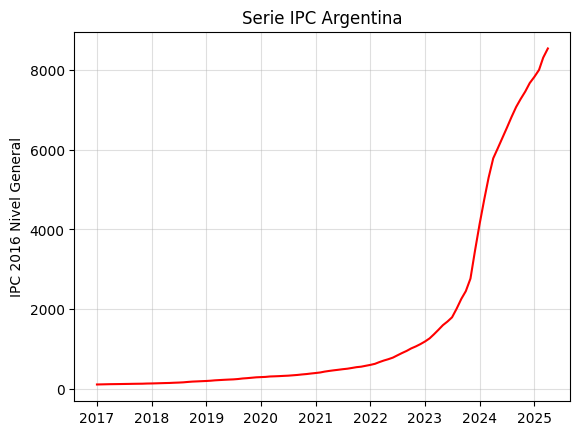

In [4]:
df = obtener_serie_ipc()
print(df.head())

#Grafico de la serie en nivel del IPC
plt.title("Serie IPC Argentina")
plt.plot(df.index, df.values, color='red')
plt.ylabel('IPC 2016 Nivel General')
plt.grid(alpha=0.4)

##### Calculo de la inflacion mensual

               ipc_2016_nivel_general  inflacion_mensual
indice_tiempo                                           
2017-02-01                   103.8085           0.024632
2017-03-01                   106.2627           0.023642
2017-04-01                   109.0613           0.026337
2017-05-01                   110.4607           0.012831
2017-06-01                   111.9943           0.013884


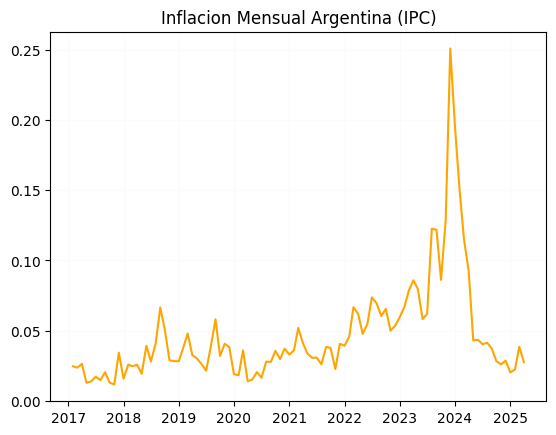

In [5]:
df['inflacion_mensual'] =(
    (  df['ipc_2016_nivel_general']/
       (df['ipc_2016_nivel_general']).shift(1)
    ) 
    - 1
    )
#Elimino los valores nulos, eliminando la primera columna
df = df.iloc[1:,]
print(df.head())

#Grafico la inflacion mensual
plt.title('Inflacion Mensual Argentina (IPC)')
plt.plot(df.index, df['inflacion_mensual'], color='orange')
plt.grid(alpha=0.04)


### Analisis de Estacionariedad

##### Serie nivel IPC

'\nLas autocorrelaciones no caen rapidamente mientras que la autocorelacion parcial es \nestadisticamente significativa, solo, para el primer rezago. Lo cual se asemeja a un\nproceso de caminata aleatoria (no estacionario)\n'

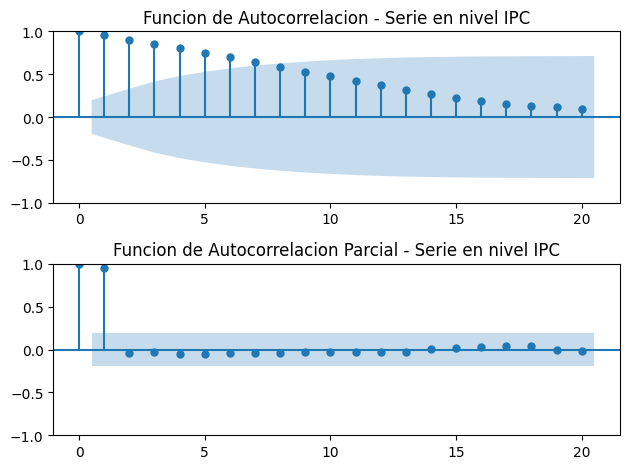

In [6]:
"""
A simple vista la serie no parece estacionaria, debido a una media no constante
a lo largo del tiempo
"""

#Analizo los graficos de autocorrelacion y autocorrelacion parcial
fig, ax = plt.subplots(2,1)

plot_acf(df['ipc_2016_nivel_general'], ax=ax[0], alpha=0.05)
ax[0].set_title('Funcion de Autocorrelacion - Serie en nivel IPC')

plot_pacf(df['ipc_2016_nivel_general'],ax=ax[1], alpha=0.05)
ax[1].set_title('Funcion de Autocorrelacion Parcial - Serie en nivel IPC')

plt.tight_layout()

"""
Las autocorrelaciones no caen rapidamente mientras que la autocorelacion parcial es 
estadisticamente significativa, solo, para el primer rezago. Lo cual se asemeja a un
proceso de caminata aleatoria (no estacionario)
"""


In [7]:
#Diagnóstico formal de estacionariedad para el IPC
determinar_orden_integracion(df["ipc_2016_nivel_general"], 
                             nombre_serie="IPC Argentina", max_d=3)

 EVALUACIÓN DE ORDEN DE INTEGRACIÓN I(d): IPC Argentina

--- Evaluando Niveles (d=0) ---
   Espec. Seleccionada: Modelo 2 (Solo Constante/Drift)
   Estadístico ADF: 1.5122 | p-value: 0.9976
   Result: NO es estacionaria en d=0 (p-value = 0.9976 >= 0.05).

--- Evaluando Diferencia d=1 ---
   Espec. Seleccionada: Modelo 2 (Solo Constante/Drift)
   Estadístico ADF: -0.9028 | p-value: 0.7870
   Result: NO es estacionaria en d=1 (p-value = 0.7870 >= 0.05).

--- Evaluando Diferencia d=2 ---
   Espec. Seleccionada: Modelo 1 (Sin componentes determinísticos)
   Estadístico ADF: -3.4428 | p-value: 0.0006

--> CONCLUSIÓN: La serie 'IPC Argentina' es ESTACIONARIA en d=2.
    Pasa la prueba con especificación: Modelo 1 (Sin componentes determinísticos) (p-value = 0.0006 < 0.05)
    ORDEN DE INTEGRACIÓN FINAL: I(2) -> Usar d = 2 en ARIMA.


{'d': 2,
 'detalles': {'modelo': 'Modelo 1 (Sin componentes determinísticos)',
  'adf_stat': np.float64(-3.4427737133047662),
  'p_value': np.float64(0.0005936778455089375),
  'estacionaria': np.True_,
  'lags': 11}}

1. Naturaleza teórica de la serie 'y' falla en niveles nominales\
Al evaluar la serie del Nivel General del IPC en niveles(y_t), el 
algoritmo determinó un orden I(2). Si bien matemáticamente la 
segunda diferencia (Delta^2 y_t) alcanza la estacionariedad, desde una perspectiva 
económica esto implica modelar la aceleración absoluta de los precios en pesos 
en lugar de la tasa de inflación mensual. Esta sobrediferenciación introduce raíces 
unitarias artificiales en el componente de medias móviles (MA) del modelo final.

2. Justificación del comportamiento del test ADF\
El resultado I(2) sobre la serie se debe a la heterocedasticidad de la varianza que rompe con los supuestos de homocedasticidad del test ADF, provocando que el criterio de selección por AIC elija un número elevado de rezagos (p aprox 11) que reduce la potencia del test, confundiendo la varianza creciente con no estacionariedad en la media.

3. Solución vía transformación logarítmica (ln y_t)\
Para resolver la heterocedasticidad. A su vez la primera diferencia del logaritmo representa la tasa de inflación continua (Delta ln y_t approx pi_t). 

##### Serie logaritmo del IPC

In [8]:
#Transformación logarítmica de la serie en niveles
df["log_ipc"] = np.log(df["ipc_2016_nivel_general"])

#Evaluación
resultado_log_ipc = determinar_orden_integracion(df["log_ipc"].dropna(),
                                    nombre_serie="Log(IPC) Argentina", max_d=3)

 EVALUACIÓN DE ORDEN DE INTEGRACIÓN I(d): Log(IPC) Argentina

--- Evaluando Niveles (d=0) ---
   Espec. Seleccionada: Modelo 2 (Solo Constante/Drift)
   Estadístico ADF: 0.8682 | p-value: 0.9927
   Result: NO es estacionaria en d=0 (p-value = 0.9927 >= 0.05).

--- Evaluando Diferencia d=1 ---
   Espec. Seleccionada: Modelo 2 (Solo Constante/Drift)
   Estadístico ADF: -2.4751 | p-value: 0.1216
   Result: NO es estacionaria en d=1 (p-value = 0.1216 >= 0.05).

--- Evaluando Diferencia d=2 ---
   Espec. Seleccionada: Modelo 1 (Sin componentes determinísticos)
   Estadístico ADF: -5.1661 | p-value: 0.0000

--> CONCLUSIÓN: La serie 'Log(IPC) Argentina' es ESTACIONARIA en d=2.
    Pasa la prueba con especificación: Modelo 1 (Sin componentes determinísticos) (p-value = 0.0000 < 0.05)
    ORDEN DE INTEGRACIÓN FINAL: I(2) -> Usar d = 2 en ARIMA.


El $p$-valor de $0.1216$ en $d=1$ revela por qué el test ADF falla incluso tras aplicar logaritmos debido a la presencia de un quiebre estructural de régimen en la inflación.Al haber una aceleración marcada de la inflación en la serie, el test ADF estándar confunde el salto en la media de $\Delta \ln(\text{IPC}_t)$ con no-estacionariedad. Como la función utiliza autolag='AIC', esta sobrecarga la regresión con $11$ o $12$ rezagos para intentar blanquear los errores del quiebre, perdiendo potencia estadística y concluyendo $I(2)$. Por ende, respaldados en la teoría económica (la inflación es estacionaria en torno a su media de régimen), fijamos metodológicamente $d=1$ para la estimación del modelo ARIMA